# Causalidad para practicantes de Machine Learning

**Sesión 10 · Causalidad para Machine Learning**

En el notebook anterior distinguíamos datos observados de relaciones causales conocidas por su capacidad predictiva. En esta sesión damos un paso más: utilizamos la causalidad para explicar cuándo una asociación puede confundirse con un efecto, cómo representar relaciones causales y cómo estimar una intervención a partir de datos observacionales.

Partimos de un hospital sintético con asma, ingreso en UCI y mortalidad. A partir de un conjunto de mecanismos autónomos, construiremos un modelo causal estructural y lo utilizaremos para comparar asociaciones, ajustes por confusión, intervenciones simuladas y cambios de entorno.

La pregunta central es por qué **una buena predicción no basta para tomar decisiones** ni garantiza que un modelo funcione en otro entorno. El notebook combina grafos causales, contrafactuales, mecanismos de SCM y estimación con DoWhy.

**Contenido**

1. Asociación, intervención y contrafactual
2. La paradoja del asma y el ajuste por confusión
3. Representación causal mediante DAG y modelos estructurales
4. Intervenciones y estimación del efecto causal
5. Cambios de mecanismos y robustez fuera de distribución
6. Identificación y estimación causal con DoWhy
7. Refutación de estimaciones y conclusiones

> ### Inferencia Causal
 
>La inferencia causal tiene sus raíces en la filosofía y la estadística de los siglos XVIII y XIX. David Hume planteó el problema fundamental de la causalidad: observar que dos fenómenos ocurren conjuntamente no demuestra que uno sea la causa del otro. En el siglo XIX, John Stuart Mill propuso métodos sistemáticos para identificar relaciones causales mediante la comparación de situaciones. Posteriormente, Francis Galton y Karl Pearson desarrollaron herramientas estadísticas como la **correlación y la regresión**, que permitían cuantificar **asociaciones entre variables** (hay asociación si $P(Y\mid X)\neq P(Y)$), pero no establecer por sí solas relaciones de causa y efecto.

> Durante el siglo XX, la inferencia causal se desarrolló especialmente a través del **diseño de experimentos** y la estadística. Ronald Fisher formalizó el uso de la aleatorización en experimentos, mientras que Jerzy Neyman introdujo en 1923 una formulación basada en resultados potenciales. Este enfoque, desarrollado posteriormente por Donald Rubin, define el efecto causal comparando qué ocurriría a una misma unidad con tratamiento y sin tratamiento. Paralelamente, Sewall Wright introdujo los diagramas de caminos para representar relaciones causales, anticipando el uso moderno de los grafos causales.

> A partir de los años noventa, Judea Pearl impulsó una nueva formulación matemática de la causalidad basada en grafos y modelos causales estructurales (SCM). Su aportación consistió en integrar la representación gráfica de las relaciones causales con un lenguaje formal para estudiar intervenciones y contrafactuales. Mediante el operador $do(X=x)$ y el `do-calculus`, Pearl estableció reglas para determinar **cuándo es posible identificar efectos causales a partir de datos observacionales**. Este enfoque contribuyó a convertir la inferencia causal en una disciplina con herramientas matemáticas y algorítmicas propias, hoy fundamentales en ciencia de datos.

In [16]:
# Dependencias principales: numpy, pandas, matplotlib, scikit-learn, networkx, dowhy
import warnings
# Evita el aviso de tqdm (barras de progreso de DoWhy) cuando ipywidgets no está instalado
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import dowhy
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss

plt.rcParams.update({"figure.figsize": (4, 2), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
SEED = 42

# 0. La paradoja del asma

## Antes de empezar: ¿qué es la causalidad?

Decimos que **$X$ causa $Y$** si, al **modificar $X$ en el mundo real** (sin tocar nada más), **$Y$ cambia**. 

El concepto clave es *modificar sin tocar nada más*: una afirmación causal habla de lo que pasaría si **interviniéramos**, no solo de lo que observamos que ocurre a la vez.

> En el caso del ML asumimos siempre que no intervenimos en el mundo que hemos observado, que el mundo va desplegándose tal y como lo hacía cuando lo observamos.

> Un modelo de ML aprende **regularidades** del tipo «cuando aparece $X$, suele aparecer $Y$». Para *predecir* (estimar qué resultado es probable que ocurra a partir de las regularidades observadas en los datos, $\mathbb{E}[Y|X, Z, \dots]$), es suficiente; para *decidir*, muchas veces no lo es. 

Ejemplo clásico: los días en que se venden más helados hay más ahogamientos. La asociación es real y sirve para **predecir**, pero prohibir los helados (**intervención**) no evitaría ahogamientos: ambas cosas aumentan por un tercer factor, el calor (una **causa común** o **variable de confusión**).

En cambio, intervenir sobre una causa directa puede tener sentido: si queremos reducir las quemaduras solares, podemos promover el uso de protector solar. Aquí la intervención cambia una causa plausible de la quemadura, no una variable que solo está asociada con ella.

| Pregunta predictiva (relacionada con una observación)| Pregunta causal (relacionada con una intervención)|
|---|---|
| ¿Los pacientes tienen más riesgo de morir si presentan un síntoma $X$? | ¿Cuántas muertes evitaríamos si ingresáramos en UCI a los pacientes que presentan $X$? |
| ¿Qué clientes se darán de baja de mi servicio? | ¿Qué clientes se quedarían si les ofreciéramos un descuento? |
| ¿Qué anuncios reciben más clics? | ¿Cuántos clics *adicionales* genera mostrar este anuncio en vez de este otro? |

+ Las preguntas de la izquierda corresponden al mundo **observacional** y el ML es una buena opción para generar la respuesta (siempre y cuando el mundo continúe comportándose de forma igual).

+ Las preguntas de la derecha son las que importan cuando un modelo se usa para **decidir una intervención**, y intervenir cambia la distribución de los datos de entrenamiento.

Responder a una pregunta causal requiere tres ingredientes:
1. **Una descripción** precisa sobre la intervención: «¿qué pasa si hacemos $X$?».
2. **Supuestos** sobre cómo se generan los datos, que representaremos con un **grafo**.
3. **Datos** observacionales para calcular el resultado.

Con estos ingredientes podemos, **a veces**, dar una respuesta a ese tipo de preguntas. El proceso que determina si se puede dar la respuesta o no se llama **identificación**. 

> Los datos solos, por muchos que sean, no bastan para responder una pregunta causal. Una asociación entre $X$ e $Y$ puede ser compatible con explicaciones distintas: $X$ causa $Y$, $Y$ causa $X$ o una tercera variable causa ambas. Por eso, los datos observacionales, por sí solos, no suelen determinar un único grafo causal. Para escoger entre explicaciones necesitamos supuestos adicionales, conocimiento del problema o datos de intervenciones.

La historia siguiente muestra lo que puede ocurrir cuando se olvida.

## La historia real

En los años 90 se entrenaron varios modelos de ML para predecir el riesgo de muerte de los pacientes con neumonía. La idea era usarlos para decidir quién podía tratarse en casa y quién debía ingresar. 

Uno de esos modelos aprendió una regla sorprendente: **tener asma reduce el riesgo de morir** (Caruana et al., 2015).

La regla era correcta *en los datos* (**observación**): la regularidad detectada era que los asmáticos con neumonía morían menos. Pero no porque el asma proteja, sino por cómo actuaban los médicos en ese hospital:
- sabían que el asma es un factor de riesgo, así que en muchos casos ingresaban a los asmáticos directamente en la UCI;
- en la UCI se suministraba un tratamiento intensivo que les reducía tanto el riesgo que acababan muriendo menos que el resto.

Si se hubiera usado el modelo para decidir quién ingresa, habría mandado a casa precisamente a los pacientes que más necesitaban la UCI.

En este notebook reproducimos esa situación con datos simulados.

## El problema

Trabajas en el hospital 1. Un modelo de predicción usa el hecho de que los pacientes que **ingresan por neumonía** con asma tienen **menor mortalidad observada** entre quienes ingresan simplemente por neumonía.

Empecemos únicamente por lo que ve un analista: datos observacionales. No comentaremos aún el mecanismo que los generó.

Variables observadas: `H`=hospital, `A`=asma, `U`=UCI, `M`=muerte, `R`=registro posterior


In [17]:
class HospitalSCM:
    """Hospital sintético: A=asma, U=UCI, M=muerte, R=registro, H=hospital.

    Mecanismos autónomos con ruido exógeno independiente. `do` sustituye un mecanismo.
    """
    P_ASMA = 0.30
    RIESGO = {(0, 0): 0.10, (0, 1): 0.03, (1, 0): 0.30, (1, 1): 0.04}
    POLITICA = {1: (0.05, 0.95), 2: (0.15, 0.75), 3: (0.15, 0.15)}
    PROTOCOLO = {1: 2.0, 2: 1.0, 3: 0.0}
    NOMBRES = {1: "1", 2: "2", 3: "3"}

    def __init__(self, seed=SEED):
        self.rng = np.random.default_rng(seed)

    def sample(self, n, H=1, do=None):
        do = {} if do is None else dict(do)
        rng = self.rng
        a = np.full(n, do["A"], dtype=int) if "A" in do else (rng.random(n) < self.P_ASMA).astype(int)
        p0, p1 = self.POLITICA[H]
        u = np.full(n, do["U"], dtype=int) if "U" in do else (rng.random(n) < np.where(a, p1, p0)).astype(int)
        p_m = np.array([self.RIESGO[(int(ai), int(ui))] for ai, ui in zip(a, u)])
        m = np.full(n, do["M"], dtype=int) if "M" in do else (rng.random(n) < p_m).astype(int)
        r = np.full(n, do["R"], dtype=float) if "R" in do else self.PROTOCOLO[H] * m + rng.normal(size=n)
        return pd.DataFrame({"H": H, "A": a, "U": u, "M": m, "R": r})

scm = HospitalSCM(SEED)
N = 30_000
datos = {HospitalSCM.NOMBRES[h]: scm.sample(N, H=h) for h in (1, 2, 3)}
H1, H2, H3 = datos["1"], datos["2"], datos["3"]
print("Variables observadas: H=hospital, A=asma, U=UCI, M=muerte, R=registro posterior")
display(H1.head())

Variables observadas: H=hospital, A=asma, U=UCI, M=muerte, R=registro posterior


,H,A,U,M,R
0,1,0,0,0,-0.711
1,1,0,0,0,2.360
2,1,0,0,0,-1.169
3,1,0,0,0,0.507
4,1,1,1,0,-1.885


En el dataset la variable `R` es un registro/marcador de la historia clínica (número real), tal como una anotación o un código que se registra cuando el paciente evoluciona mal, por ejemplo en el informe de alta:
  - Es una **consecuencia** del desenlace.
  - Predice muy bien `M`, pero cuánto lo refleja depende de cómo codifica cada hospital.

Vamos primero a analizar el riesgo de morir en función del asma, $P(M=1|A)$.

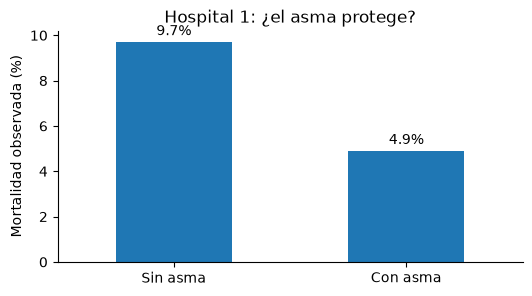

,Mortalidad observada
A,
Sin asma,0.097
Con asma,0.049


In [18]:
mortalidad = H1.groupby("A")["M"].mean().rename(index={0: "Sin asma", 1: "Con asma"})
fig, ax = plt.subplots(figsize=(6, 3))
mortalidad.mul(100).plot.bar(ax=ax, rot=0)
ax.set(ylabel="Mortalidad observada (%)", xlabel="", title="Hospital 1: ¿el asma protege?")
for i, v in enumerate(mortalidad.values): ax.text(i, v*100 + .3, f"{v:.1%}", ha="center")
plt.show()
display(mortalidad.to_frame("Mortalidad observada"))

Hay una asociación $P(M=1|A)$ observada, que depende de la política del hospital, que puede ser usada por un sistema de ML que se basa en $P(M=1|A,H,U,R)$ para hacer una predicción del riesgo del paciente a partir de todas las variables disponibles. 

Un modelo de ML condicionado a la política actual no sirve para hacer una predicción del riesgo de un paciente que ha sido tratado con una política distinta.

### Segundo dato: la UCI
Ahora **estratificamos** la mortalidad según la decisión asistencial (**estratificar** significa dividir los datos en grupos según una variable y analizar cada grupo por separado): $P(M=1|A,U)$. 

Aquí comparamos la mortalidad de pacientes con y sin asma entre quienes ingresaron en la UCI y, por separado, entre quienes no ingresaron. 

¿Sigue pareciendo protectora el asma *dentro de cada grupo*? 

U,Sin UCI,Con UCI
A,,
Sin asma,10.1%,2.0%
Con asma,27.8%,3.7%


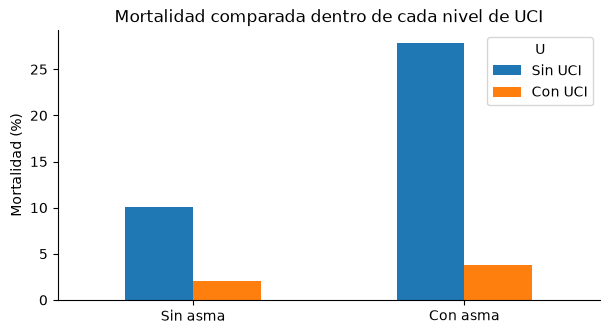

Proporción de pacientes enviados a UCI según asma:


,P(UCI)
A,
Sin asma,0.050
Con asma,0.952


In [19]:
tabla = H1.groupby(["A", "U"])["M"].mean().unstack()
tabla = tabla.rename(index={0:"Sin asma",1:"Con asma"}, columns={0:"Sin UCI",1:"Con UCI"})
display(tabla.style.format("{:.1%}"))
fig, ax = plt.subplots(figsize=(7, 3.5))
(tabla * 100).plot.bar(ax=ax, rot=0)
ax.set(ylabel="Mortalidad (%)", xlabel="", title="Mortalidad comparada dentro de cada nivel de UCI")
plt.show()
print("Proporción de pacientes enviados a UCI según asma:")
display(H1.groupby("A")["U"].mean().rename(index={0:"Sin asma",1:"Con asma"}).to_frame("P(UCI)"))

**Interpretación:** dentro de cada grupo (con y sin UCI), los pacientes con asma tienen **mayor** mortalidad: el asma no protege. Pero los pacientes con asma ingresan mucho más en UCI, y la UCI reduce su riesgo. La política asistencial puede invertir la comparación marginal de mortalidad.

**Idea clave:** las asociaciones observadas por el modelo de ML son propiedades de una distribución *bajo una política concreta*. No equivalen por sí solas a efectos de intervenir. 

---
# 1. Construimos el hospital como mecanismos

Ahora vamos a hacer una hipótesis sobre cómo se generan los datos en el mundo real. Esto lo representaremos con un grafo **DAG** (Directed Acyclic Graph).

**Importante**: los datos observados no determinan por sí solos las flechas de un DAG. Una misma asociación puede encajar con estructuras causales distintas; las flechas representan hipótesis sobre los mecanismos, apoyadas por conocimiento del problema y supuestos adicionales. En este notebook adoptaremos un DAG concreto para el simulador: no porque los datos lo demuestren por sí solos, sino porque hacemos una hipótesis sobre cómo se generaron.

El DAG de los datos del hospital contiene cinco variables:

- `A`: presencia de asma, antes de la decisión.
- `U`: ingreso en UCI (tratamiento).
- `M`: desenlace (muerte).
- `H`: hospital (cambia políticas y registros).
- `R`: marcador del registro de alta, **medido después de `M`**.

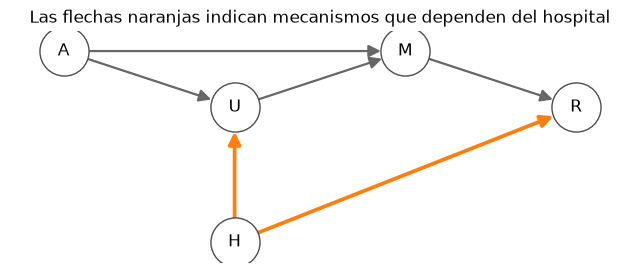

In [20]:
POS = {"A": (0, 1), "U": (1.4, 0.5), "M": (2.8, 1), "R": (4.2, 0.5), "H": (1.4, -0.7)}
ARISTAS = [("A","U"),("A","M"),("U","M"),("M","R"),("H","U"),("H","R")]
def dibuja_grafo(aristas=ARISTAS, destacadas=(), ax=None, titulo=None):
    if ax is None: _, ax = plt.subplots(figsize=(8,3))
    g = nx.DiGraph(); g.add_nodes_from(POS); g.add_edges_from(aristas)
    nx.draw_networkx(g, POS, ax=ax, node_size=1250, node_color="white", edgecolors="0.3",
        edge_color=["tab:orange" if e in destacadas else "0.4" for e in g.edges],
        width=[2.7 if e in destacadas else 1.6 for e in g.edges], arrows=True, arrowsize=18)
    ax.set_title(titulo or "Grafo causal del hospital")
    ax.axis("off")
    return ax

dibuja_grafo(destacadas=[("H","U"),("H","R")], titulo="Las flechas naranjas indican mecanismos que dependen del hospital")
plt.show()

## De un grafo a ecuaciones estructurales

Una flecha no es una asociación entre dos variables dibujada: expresa que la variable participa en el **mecanismo del mundo real que genera** otra.

$$ A := f_A(\varepsilon_A),\quad U := f_U(A,H,\varepsilon_U),\quad M := f_M(A,U,\varepsilon_M),\quad R := f_R(M,H,\varepsilon_R). $$

En un **modelo causal estructural** (SCM), cada variable se genera mediante una función que depende de sus causas directas y de un término de ruido $\varepsilon$. Por ejemplo, el término $\varepsilon_M$ representa todos los factores que influyen en la mortalidad y que no hemos incluido explícitamente en el modelo: diferencias individuales, características clínicas no representadas y otros elementos que hacen que dos pacientes con el mismo estado de asma y el mismo tratamiento puedan tener resultados distintos.

En el caso de $H$, en una población real habría un mecanismo de asignación de pacientes a los hospitales, con su propio ruido $\varepsilon_H$. En el simulador lo sustituimos fijando directamente el hospital: $H:=h$.

> Un matiz importante: en el simulador, $H$ es una variable cuya asignación es independiente de los demás ruidos. En la realidad, la elección del hospital podría depender de factores como la gravedad del paciente, su lugar de residencia o la disponibilidad de camas. En ese caso, necesitaríamos un modelo causal más complejo.

El modelo contiene cinco variables:
- $H$: hospital (1, 2 o 3).
- $A$: asma (0 = no, 1 = sí).
- $U$: ingreso en UCI (0 = no, 1 = sí).
- $M$: mortalidad (0 = sobrevive, 1 = muere).
- $R$: marcador continuo del registro hospitalario.

Las ecuaciones estructurales son:

$$
\begin{aligned}
H &:= h \\[4pt]
A &:= \mathbb{1}[\varepsilon_A<0.30] \\[4pt]
U &:= \mathbb{1}[\varepsilon_U<p_U(A,H)] \\[4pt]
M &:= \mathbb{1}[\varepsilon_M<p_M(A,U)] \\[4pt]
R &:= \alpha_H M+\varepsilon_R
\end{aligned}
$$

donde los ruidos exógenos son independientes ($\varepsilon_A,\varepsilon_U,\varepsilon_M
\overset{\mathrm{iid}}{\sim}\mathcal U(0,1)$, $\varepsilon_R\sim\mathcal N(0,1)$) y:

$$
\alpha_H=
\begin{cases}
2 & \text{si }H=1\\
1 & \text{si }H=2\\
0 & \text{si }H=3
\end{cases}
$$

Las probabilidades $p_U(A,H)$ y $p_M(A,U)$ son constantes predefinidas en el modelo, especificadas en los diccionarios `POLITICA` y `RIESGO`:

- `POLITICA = {1: (0.05, 0.95), 2: (0.15, 0.75), 3: (0.15, 0.15)}`: para cada hospital, probabilidad de ingreso en UCI sin asma y con asma, $p_U(A,H)$.
- `RIESGO = {(0, 0): 0.10, (0, 1): 0.03, (1, 0): 0.30, (1, 1): 0.04}`: probabilidad de muerte para cada combinación $(A,U)$, $p_M(A,U)$.

Por tanto:
- Si el paciente sobrevive ($M=0$), entonces $R=\varepsilon_R$, independientemente del hospital.
- Si el paciente muere ($M=1$), entonces $R=\alpha_H+\varepsilon_R$. El valor esperado de $R$ depende del hospital.

El hospital $H=h$ se fija al llamar a `sample()`, por lo que no se genera aleatoriamente en este simulador.

### Del grafo a la distribución de probabilidades

En el caso de los datos generados según estos mecanismos, se puede demostrar que la distribución observacional $P(H,A,U,M,R)$ se puede factorizar como:

$$
P(H,A,U,M,R)=P(H)\,P(A)\,P(U\mid A,H)\,P(M\mid A,U)\,P(R\mid M,H).
$$

En el notebook fijamos `H` al generar el hospital; la expresión anterior corresponde a una población con diversos entornos (hospitales).

**Lo importante:** podemos cambiar una ecuación sin modificar las demás. Es lo que después llamaremos **autonomía o modularidad causal**.

| Mecanismo | Qué representa | ¿Cambia entre hospitales? |
|---|---|---|
| $P(H)$ | La probabilidad a priori de que un paciente sea asignado a un hospital determinado | - |
| $P(A)$ | La prevalencia del asma (30 %) | No |
| $P(U\mid A, H)$ | La política de ingreso en la UCI | **Sí**: el 1 ingresa a casi todos los asmáticos, el 2 a tres de cada cuatro y el 3 a muy pocos |
| $P(M\mid A, U)$ | La biología: el riesgo de morir según el asma y la UCI | No |
| $P(R\mid M, H)$ | Cómo se registra el marcador | **Sí**: en el 1 refleja mucho la muerte, en el 2 a medias y en el 3 nada |

Dicho de otra forma, pasar del hospital 1 al 3 equivale a **cambiar dos piezas** del sistema (la política y el protocolo) y dejar el resto intacto. 

In [21]:
print("Mecanismo de mortalidad, IGUAL en los tres hospitales")
risk = pd.Series(scm.RIESGO, name="P(M=1 | A,U)").rename_axis(["A", "U"]).unstack()
display(risk.rename(index={0:"Sin asma",1:"Con asma"},columns={0:"Sin UCI",1:"Con UCI"}).style.format("{:.1%}"))
print("Mecanismo de decisión de UCI, DIFERENTE entre hospitales")
pol = pd.DataFrame(scm.POLITICA, index=["Sin asma","Con asma"])
pol.columns = ["Hospital 1","Hospital 2","Hospital 3"]
display(pol.style.format("{:.0%}"))
print("Mecanismo del registro R = coeficiente · M + ruido")
display(pd.Series(scm.PROTOCOLO, index=None).rename(index=scm.NOMBRES).to_frame("Coeficiente"))

Mecanismo de mortalidad, IGUAL en los tres hospitales


U,Sin UCI,Con UCI
A,,
Sin asma,10.0%,3.0%
Con asma,30.0%,4.0%


Mecanismo de decisión de UCI, DIFERENTE entre hospitales


,Hospital 1,Hospital 2,Hospital 3
Sin asma,5%,15%,15%
Con asma,95%,75%,15%


Mecanismo del registro R = coeficiente · M + ruido


,Coeficiente
1,2.0
2,1.0
3,0.0


## Experimento 1 · Cambia una política, no la biología

Si un hospital reduce el ingreso de asmáticos en UCI, ¿aumenta o disminuye la mortalidad observada entre asmáticos? ¿Puede desaparecer la aparente «protección» del asma?

Vamos a verlo cambiando el mecanismo.



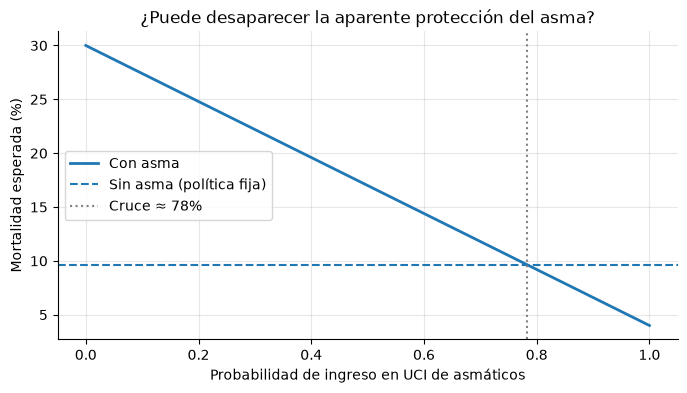

Las curvas se cruzan cuando la probabilidad de UCI de los asmáticos es ≈ 78.3%


In [22]:
r = scm.RIESGO
# Política de ingreso de pacientes no asmáticos: fija (la del hospital 1)
p_uci_sin_asma = 0.05
# Reducimos progresivamente el ingreso de asmáticos
politicas = np.linspace(1, 0, 101)
mortalidad_asma = [
    (1-p)*r[(1,0)] + p*r[(1,1)]
    for p in politicas
]
mortalidad_no_asma = (
    (1-p_uci_sin_asma)*r[(0,0)]
    + p_uci_sin_asma*r[(0,1)]
)
# Política de UCI de asmáticos para la que ambas mortalidades coinciden
p_cruce = (r[(1,0)] - mortalidad_no_asma) / (r[(1,0)] - r[(1,1)])

plt.figure(figsize=(8, 4))
plt.plot(
    politicas,
    100*np.array(mortalidad_asma),
    label="Con asma",
    linewidth=2
)
plt.axhline(
    100*mortalidad_no_asma,
    linestyle="--",
    label="Sin asma (política fija)"
)
plt.axvline(
    p_cruce,
    color="0.5",
    linestyle=":",
    label=f"Cruce ≈ {p_cruce:.0%}"
)
plt.xlabel("Probabilidad de ingreso en UCI de asmáticos")
plt.ylabel("Mortalidad esperada (%)")
plt.title("¿Puede desaparecer la aparente protección del asma?")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Las curvas se cruzan cuando la probabilidad de UCI de los asmáticos es ≈ {p_cruce:.1%}")


Las dos curvas se cruzan cuando la probabilidad de ingreso en UCI de los asmáticos es aproximadamente del **78 %**:

- Por encima de ese valor (como en el hospital 1, donde ingresa el 95 %), los asmáticos tienen **menor** mortalidad observada y el asma parece «proteger».
- Por debajo, la relación se invierte: los asmáticos tienen **mayor** mortalidad observada que los no asmáticos.

Por tanto, si un hospital reduce el ingreso de asmáticos en UCI, la mortalidad observada entre asmáticos **aumenta** y la aparente «protección» del asma desaparece. En toda la gráfica la biología $P(M\mid A,U)$ es la misma: lo único que cambia es la política.


---
# 2. Observar no es intervenir

Ahora volvamos al dataset con el fin de responder preguntas.

Podemos hacer tres preguntas distintas:

| Nivel | Pregunta | Notación |
|---|---|---|
| Asociación | ¿Qué mortalidad tienen los pacientes que **reciben** UCI? | $P(M=1\mid U=1)$ |
| Intervención (efecto causal) | ¿Qué mortalidad habría si **asignáramos** UCI a **todos los pacientes**? | $P(M=1\mid do(U=1))$ |
| Contrafactual individual | Este paciente recibió UCI y sobrevivió: ¿habría sobrevivido sin ella? | $M_{U\leftarrow 0}\mid U=1,M=0$ |

Es muy importante darse cuenta de que al realizar `do(U=u)` sustituimos la ecuación que determina `U`. Cortamos `A→U` y `H→U`, pero **no** quitamos las flechas que salen de `U`.

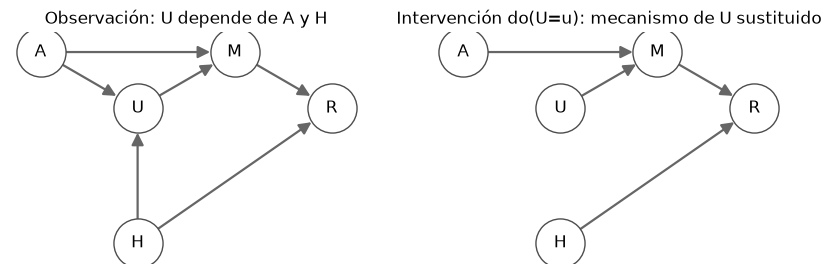

In [23]:
fig, axs=plt.subplots(1,2,figsize=(10,3))
dibuja_grafo(ax=axs[0],titulo="Observación: U depende de A y H")
dibuja_grafo(aristas=[e for e in ARISTAS if e[1]!="U"], ax=axs[1],titulo="Intervención do(U=u): mecanismo de U sustituido")
plt.show()

Dos variables $X$ e $Y$ están asociadas cuando conocer $X$ cambia la probabilidad de $Y$:

$$
P(Y\mid X)\neq P(Y).
$$

Pero una asociación no implica necesariamente causalidad. Hablamos de asociación espuria cuando $X$ e $Y$ están asociadas, pero cambiar $X$ no provoca ningún cambio en $Y$:

$$
P(Y\mid X=x)\neq P(Y),
\qquad
P(Y\mid do(X=x))=P(Y).
$$

Por ejemplo, una causa común puede generar una asociación:

$$
X\leftarrow Z\rightarrow Y.
$$

En nuestro modelo hospitalario, la asociación entre hospital $H$ y mortalidad $M$ no es espuria, porque existe un camino causal:

$$
H\rightarrow U\rightarrow M.
$$


La idea clave es que observar una variable no es lo mismo que intervenir sobre ella. Por eso, en general,

$$
P(Y\mid X=x)\neq P(Y\mid do(X=x)).
$$

Un modelo de ML entrenado con datos observacionales aprende asociaciones de la política actual. Si cambiamos esa política mediante una intervención, esas asociaciones pueden cambiar y el modelo puede dejar de funcionar correctamente.

## Experimento 2 · Tres estimaciones del efecto de UCI

Queremos estimar **el efecto causal del ingreso en UCI sobre la mortalidad**. Es decir, queremos saber si ingresar a un paciente en UCI cambia su probabilidad de morir.

En concreto, queremos estimar el **efecto medio del tratamiento** (ATE, *average treatment effect*): la diferencia entre la mortalidad que habría si ingresáramos en UCI a todos los pacientes y la que habría si no ingresáramos a ninguno,

$$
ATE = P(M=1\mid do(U=1)) - P(M=1\mid do(U=0)).
$$

Un valor negativo significa que el ingreso en UCI reduce la mortalidad.

De forma ingenua, podríamos pensar que basta con comparar la mortalidad de los pacientes que ingresaron en UCI con la de aquellos que no ingresaron:

$$
P(M=1\mid U=1)-P(M=1\mid U=0)
$$

Sin embargo, **esta diferencia no mide necesariamente el efecto causal del ingreso en UCI**. El problema es que los pacientes que reciben el tratamiento pueden tener características diferentes de los que no lo reciben.

En nuestro ejemplo, el asma ($A$) influye tanto en la probabilidad de ingresar en UCI ($U$) como en la mortalidad ($M$). Por tanto, si observamos una diferencia de mortalidad entre ambos grupos, no sabemos si se debe al tratamiento o a las diferencias en la proporción de pacientes asmáticos.

Este problema se conoce como **confusión (*confounding*)**: una tercera variable influye tanto en el tratamiento como en el resultado, generando una asociación que puede distorsionar la estimación del efecto causal.

El **grafo causal nos permite identificar este problema**. En nuestro caso, existe un camino entre $U$ y $M$ que pasa por $A$:

$$
U\leftarrow A\rightarrow M
$$

Este camino genera una asociación entre $U$ y $M$ que no corresponde al efecto causal del tratamiento.

### ¿Cómo podemos resolverlo?

La inferencia causal proporciona métodos para determinar cuándo podemos estimar el efecto de una intervención utilizando datos observacionales. La idea fundamental es que **la estructura del grafo causal nos permite identificar qué variables debemos controlar para eliminar la confusión**.

En nuestro ejemplo, ajustar por el asma bloquea el camino de confusión entre UCI y mortalidad. Esto significa que podemos comparar pacientes con el mismo estado de asma y combinar después los resultados para obtener una estimación del efecto causal en la población.

Este procedimiento se conoce como **ajuste por variables de confusión** y, bajo las condiciones adecuadas, permite calcular el efecto de una intervención sin necesidad de realizarla.

### La fórmula de ajuste

En nuestro modelo causal, el efecto de una intervención sobre UCI puede identificarse mediante:

$$
P(M=1\mid do(U=u))=
\sum_a P(M=1\mid U=u,A=a)P(A=a)
$$

La expresión $do(U=u)$ representa una intervención hipotética en la que fijamos el ingreso en UCI a un valor determinado, en lugar de observar qué pacientes ingresaron realmente.

La fórmula nos dice que, para estimar qué mortalidad observaríamos si todos los pacientes recibieran una determinada decisión de tratamiento $u$, debemos:

1. Calcular la mortalidad entre los pacientes asmáticos y no asmáticos que recibieron ese tratamiento.
2. Ponderar cada resultado según la proporción de asmáticos y no asmáticos en la población.
3. Sumar ambos resultados.

**Es importante entender que esta fórmula es un resultado de la inferencia causal, no una identidad probabilística válida en cualquier situación.** Su validez depende de la estructura del grafo: necesitamos identificar un conjunto de variables que bloquee los caminos de confusión sin introducir nuevos sesgos.

En nuestro modelo, ajustar por $A$ es suficiente, siempre que el grafo represente correctamente las relaciones causales y existan pacientes tratados y no tratados en ambos grupos.

### Tres formas de estimar el efecto de UCI

Vamos a comparar tres estrategias:

**1. Estimación ingenua (observacional)**

Calculamos directamente la diferencia de mortalidad entre los pacientes que ingresaron en UCI y los que no ingresaron. Esta comparación puede estar sesgada porque ambos grupos tienen diferentes proporciones de pacientes asmáticos.

**2. Estimación ajustada (observacional)**

Utilizamos los mismos datos observacionales, pero **comparamos primero pacientes con las mismas características**. Calculamos por separado la mortalidad con y sin UCI entre asmáticos y no asmáticos, y después combinamos los resultados según la proporción de cada grupo en la población.

De este modo, utilizamos datos observacionales para estimar el efecto de una intervención, aplicando la fórmula de ajuste que hemos identificado a partir del grafo causal.

**3. Intervención simulada (causal)**

En este caso hacemos algo diferente: **modificamos directamente el mecanismo generador de los datos**.

Como conocemos el modelo causal estructural (SCM), podemos sustituir la ecuación que determina el ingreso en UCI por una intervención que fuerce $U=1$ para todos los pacientes, o $U=0$ para todos.

Simulamos ambos escenarios y comparamos sus mortalidades. Así obtenemos directamente el efecto causal dentro del modelo, sin necesidad de ajustar por las diferencias entre los grupos.

Esto es posible porque trabajamos con un simulador cuyo mecanismo causal conocemos. En un problema real, normalmente no podemos intervenir de esta manera sobre toda la población.

### ¿Qué esperamos observar?

Las tres aproximaciones permiten comparar la asociación observada con el efecto causal del ingreso en UCI. Como referencia, usaremos también el ATE verdadero, que podemos calcular exactamente porque conocemos el simulador:

1. **Estimación ingenua:** ¿qué diferencia de mortalidad observamos entre quienes recibieron UCI y quienes no? Esta comparación puede estar sesgada por las diferencias entre ambos grupos.

2. **Estimación ajustada:** ¿qué efecto causal podemos estimar utilizando datos observacionales y ajustando por las variables de confusión identificadas en el grafo?

3. **Intervención simulada:** ¿qué ocurre cuando modificamos el SCM para forzar el ingreso de todos los pacientes en UCI o de ninguno? Obtenemos una estimación del efecto causal mediante simulación Monte Carlo.


**En resumen:** si el grafo causal es correcto, se cumplen las condiciones de identificación y disponemos de suficientes observaciones, **la estimación ajustada y la intervención simulada deberían aproximarse al ATE verdadero**. La estimación ingenua, en cambio, puede seguir siendo diferente incluso con una cantidad muy grande de datos.

Esta comparación ilustra una idea fundamental: **más datos no eliminan necesariamente el sesgo de confusión; necesitamos un modelo causal adecuado para identificar el efecto de una intervención**.

,Diferencia de mortalidad,Puntos porcentuales
Asociación ingenua,-0.069,-6.9
Ajuste por A,-0.129,-12.9
Intervención (simulada),-0.126,-12.6
ATE verdadero (simulador),-0.127,-12.7


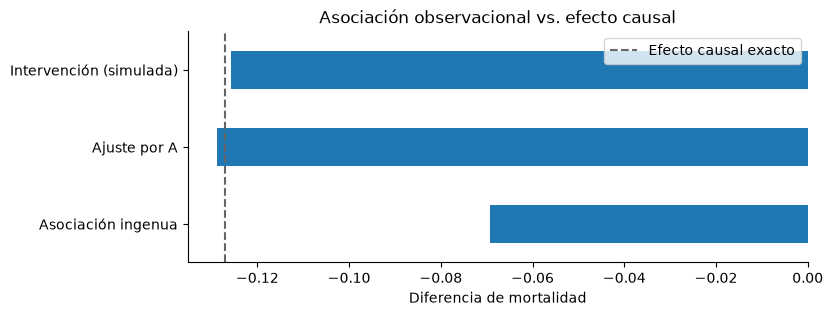

In [24]:
def riesgo_do_exact(u):
    return (
        (1 - scm.P_ASMA) * scm.RIESGO[(0, u)]
        + scm.P_ASMA * scm.RIESGO[(1, u)]
    )
ate_exact = riesgo_do_exact(1) - riesgo_do_exact(0)

# Asociación observacional ingenua
naive = (
    H1.loc[H1["U"] == 1, "M"].mean()
    - H1.loc[H1["U"] == 0, "M"].mean()
)

# Ajuste por A
p_m_au = H1.groupby(["A", "U"])["M"].mean()
p_a = H1["A"].value_counts(normalize=True)

adjusted = sum(
    p_a[a] * (p_m_au.loc[a, 1] - p_m_au.loc[a, 0])
    for a in [0, 1]
)

# Efecto causal mediante intervención simulada
m_do1 = scm.sample(100_000, H=1, do={"U": 1})["M"].mean()
m_do0 = scm.sample(100_000, H=1, do={"U": 0})["M"].mean()
ate_sim = m_do1 - m_do0

# Resultados
res = pd.Series({
    "Asociación ingenua": naive,
    "Ajuste por A": adjusted,
    "Intervención (simulada)": ate_sim
})

tabla_res = pd.concat(
    [res, pd.Series({"ATE verdadero (simulador)": ate_exact})]
).to_frame("Diferencia de mortalidad")
tabla_res["Puntos porcentuales"] = 100 * tabla_res["Diferencia de mortalidad"]
display(tabla_res.round({"Diferencia de mortalidad": 3, "Puntos porcentuales": 1}))
fig, ax = plt.subplots(figsize=(8, 3))
res.plot.barh(ax=ax)
ax.axvline(
    ate_exact,
    ls="--",
    c="0.4",
    label="Efecto causal exacto"
)
ax.set(
    xlabel="Diferencia de mortalidad",
    title="Asociación observacional vs. efecto causal"
)
ax.legend()
plt.show()

Las tres estimaciones coinciden en que el ingreso en UCI reduce la mortalidad, pero no en cuánto:

- La **asociación ingenua** subestima claramente el efecto: quienes ingresan en UCI son sobre todo asmáticos, que tienen un riesgo basal mucho mayor.
- El **ajuste por A** (que también usa solo datos observacionales) y la **intervención simulada** quedan cerca del **ATE verdadero**, $-0{,}127$: el ingreso en UCI reduce la mortalidad en unos 12,7 puntos porcentuales. Las pequeñas diferencias se deben al muestreo.

Los valores de cada estimación aparecen en la tabla anterior.


---
# 3. Mecanismos autónomos y cambios de entorno

El principio de **mecanismos causales independientes** (ICM) motiva describir el sistema como módulos autónomos: un cambio localizado puede modificar un factor sin obligar a modificar los demás. 

En nuestros hospitales:

- **Estable:** prevalencia de asma `P(A)`; biología `P(M|A,U)`.
- **Cambia:** política de UCI `P(U|A,H)`; registro `P(R|M,H)`.


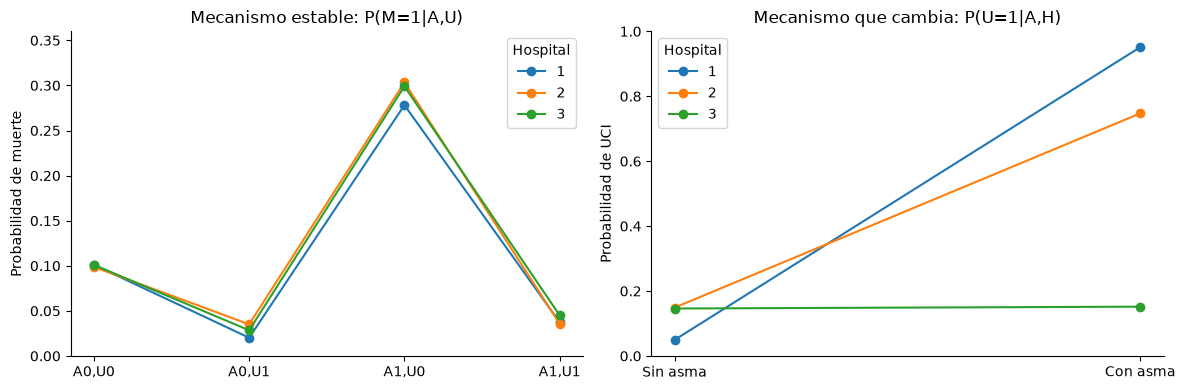

In [25]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
for h,d in datos.items():
    risks=d.groupby(["A","U"])["M"].mean()
    axs[0].plot(["A0,U0","A0,U1","A1,U0","A1,U1"],
             [risks[a,u] for a,u in [(0,0),(0,1),(1,0),(1,1)]],marker="o",label=h)
axs[0].set(title="Mecanismo estable: P(M=1|A,U)",ylabel="Probabilidad de muerte",ylim=(0,.36))
for h,d in datos.items():
    p=d.groupby("A")["U"].mean()
    axs[1].plot(["Sin asma","Con asma"],[p[0],p[1]],marker="o",label=h)
axs[1].set(title="Mecanismo que cambia: P(U=1|A,H)",ylabel="Probabilidad de UCI",ylim=(0,1))
for ax in axs: ax.legend(title="Hospital")
plt.tight_layout(); plt.show()

Los valores empíricos fluctúan por muestreo. La igualdad exacta se refiere a los mecanismos **del simulador**, no a las estimaciones finitas.

### ¿Por qué es útil la factorización causal?

La factorización causal separa los módulos `P(A)`, `P(U|A,H)`, `P(M|A,U)` y `P(R|M,H)`. Al pasar de un hospital a otro solo hay que revisar directamente los mecanismos cuyo proceso ha cambiado.

---
# 4. Experimento 3 · ¿Qué predictor resiste otro hospital?

Entrenamos tres modelos de ML sobre los hospitales 1 y 2 y los evaluamos sobre nuevos pacientes de 1+2 y sobre el hospital 3:

- **Solo usamos `A`:** parece razonable por ser variable disponible antes del ingreso, pero su relación marginal con `M` depende de la política.
- **Usamos `A,U`:** son los padres de `M` en el SCM; su mecanismo condicional es estable aquí.
- **Usamos `A,U,R`:** `R` puede hacer la predicción más fácil en los datos, pero es un registro posterior al desenlace y su relación con `M` cambia. **No es elegible para una decisión temprana** (*data leakage*).

La tercera opción es un **experimento diagnóstico sobre shortcuts**, no una propuesta racional de modelo.

,Modelo,Entorno,AUC,Log-loss
0,Solo A,1+2 (test),0.517,0.295
1,Solo A,3 (despliegue),0.352,0.427
2,"Padres A,U",1+2 (test),0.647,0.279
3,"Padres A,U",3 (despliegue),0.693,0.369
4,"A,U,R (registro posterior)",1+2 (test),0.860,0.209
5,"A,U,R (registro posterior)",3 (despliegue),0.622,0.456
6,"Ref.: P(M|A,U) verdadero",1+2 (test),0.647,0.279
7,"Ref.: P(M|A,U) verdadero",3 (despliegue),0.693,0.369


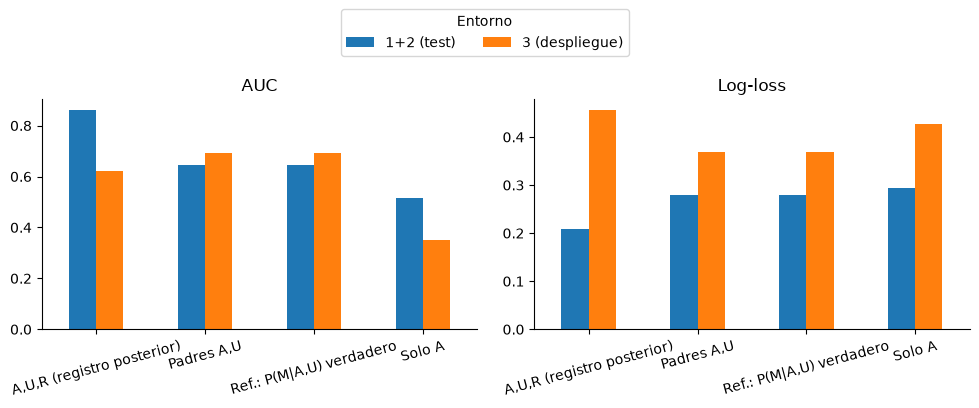

In [26]:
train = pd.concat([scm.sample(30_000,H=1),scm.sample(30_000,H=2)],ignore_index=True)
test_id = pd.concat([scm.sample(15_000,H=1),scm.sample(15_000,H=2)],ignore_index=True)
test_ood = scm.sample(30_000,H=3)
feats_dict={"Solo A":["A"],"Padres A,U":["A","U"],"A,U,R (registro posterior)":["A","U","R"]}
filas=[]
for name, features in feats_dict.items():
    model=HistGradientBoostingClassifier(max_iter=100,random_state=SEED).fit(train[features],train["M"])
    for entorno, d in [("1+2 (test)",test_id),("3 (despliegue)",test_ood)]:
        proba=model.predict_proba(d[features])[:,1]
        filas.append({"Modelo":name,"Entorno":entorno,"AUC":roc_auc_score(d["M"],proba),"Log-loss":log_loss(d["M"],proba)})
# Referencia (no es un modelo entrenado): el mecanismo verdadero P(M=1|A,U) del simulador
for entorno, d in [("1+2 (test)",test_id),("3 (despliegue)",test_ood)]:
    proba=np.array([scm.RIESGO[(a,u)] for a,u in zip(d["A"],d["U"])])
    filas.append({"Modelo":"Ref.: P(M|A,U) verdadero","Entorno":entorno,"AUC":roc_auc_score(d["M"],proba),"Log-loss":log_loss(d["M"],proba)})
resultados=pd.DataFrame(filas)
display(resultados.round(3))
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
for ax,metric in zip(axs,["AUC","Log-loss"]):
    resultados.pivot(index="Modelo",columns="Entorno",values=metric).plot.bar(ax=ax,rot=15,legend=False)
    ax.set(title=metric,xlabel="")
fig.legend(*axs[0].get_legend_handles_labels(),title="Entorno",loc="lower center",ncol=2,bbox_to_anchor=(0.5,1.0))
plt.tight_layout();plt.show()

### ¿Qué muestran los resultados?

- **Solo `A`:** en el test (hospitales 1+2) apenas supera el azar, y en el hospital 3 su AUC cae por debajo de 0,5: ordena a los pacientes al revés. El modelo aprendió que el asma «protege» porque en los hospitales 1 y 2 casi todos los asmáticos van a UCI; en el hospital 3 casi ninguno ingresa y el asma pasa a asociarse con mayor mortalidad.
- **Padres `A,U`:** su AUC se mantiene (incluso mejora) en el hospital 3. Su log-loss empeora, pero prácticamente coincide con el de la referencia (el mecanismo verdadero $P(M\mid A,U)$): el modelo sigue siendo el mejor posible con esas variables. El aumento se debe a que en el hospital 3 la mortalidad base es más alta, no a que el modelo haya dejado de funcionar.
- **`A,U,R`:** es el mejor en el test gracias al atajo que ofrece `R`, pero en el hospital 3, donde `R` ya no refleja la muerte, su rendimiento cae y su log-loss es el peor de todos.


### Dos nociones que no debemos confundir

1. **Invariancia condicional:** el mecanismo `P(M|A,U)` permanece igual en este SCM. En términos ideales se puede reutilizar entre hospitales.
2. **Estabilidad de la métrica:** AUC y log-loss pueden cambiar porque la distribución de `A,U,M` cambia, aunque el mecanismo condicional sea invariante. Las métricas miden algo más que la estabilidad de una función.

---
# 5. Experimento 4 · De los datos observacionales al efecto causal con DoWhy

Hasta ahora hemos calculado el efecto de UCI manualmente y lo hemos contrastado con intervenciones en nuestro hospital **sintético**. En ciencia de datos, una herramienta como **DoWhy** permite organizar el análisis en cuatro etapas: **modelar, identificar, estimar y refutar**.

**Pregunta:** ¿cuánto cambia la mortalidad si ingresamos a todos los pacientes en UCI, frente a no ingresar a ninguno?

El objetivo es estimar el **efecto medio del tratamiento (ATE)**, expresado como diferencia de probabilidades de muerte. Un valor negativo significa que el ingreso en UCI reduce la mortalidad.

No usaremos `R` (registro posterior a la mortalidad), ni `H` (hospital), porque trabajamos exclusivamente con el hospital 1. Para esta población basta el subgrafo causal entre **asma (`A`), UCI (`U`) y mortalidad (`M`)**:

`A → U`, `A → M`, `U → M`.

> **Nota sobre nombres:** en sus mensajes, DoWhy reserva la letra `U` para los posibles confusores **no observados**. Para evitar confusiones, en esta sección renombramos la columna de UCI como `UCI`. El grafo queda: `A → UCI`, `A → M`, `UCI → M`.

### Paso 1 · Modelar

Especificamos el tratamiento `UCI`, el efecto `M` y el **grafo causal supuesto**. El grafo no se descubre automáticamente a partir de estas observaciones: representa nuestro conocimiento del problema. Aquí sabemos que es correcto porque diseñamos el simulador.

In [27]:
from dowhy import CausalModel

grafo_dowhy = """
digraph {
    A -> UCI;
    A -> M;
    UCI -> M;
}
"""

modelo_dowhy = CausalModel(
    data=H1[["A", "U", "M"]].rename(columns={"U": "UCI"}),
    treatment="UCI",
    outcome="M",
    graph=grafo_dowhy
)


### Paso 2 · Identificar

DoWhy analiza los caminos del grafo para determinar si el efecto de `do(UCI)` puede expresarse mediante probabilidades observables. En este caso, el camino de confusión `UCI ← A → M` queda bloqueado al ajustar por `A`. Esta conclusión depende de que el grafo sea correcto y de que haya **positividad**: pacientes con y sin UCI en ambos niveles de asma.

En la salida, `U` designa un posible confusor no observado: el supuesto de *unconfoundedness* dice que no existe ninguno que afecte a la vez a `UCI` y a `M`.

In [28]:
estimando_dowhy = modelo_dowhy.identify_effect()
print(estimando_dowhy)


Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d           
──────(E[M|A])
d[UCI]        
Estimand assumption 1, Unconfoundedness: If U→{UCI} and U→M then P(M|UCI,A,U) = P(M|UCI,A)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
  d           
──────(E[M|A])
d[UCI]        
Estimand assumption 1, Unconfoundedness: If U→{UCI} and U→M then P(M|UCI,A,U) = P(M|UCI,A)



### Paso 3 · Estimar

Aplicamos un **estimador de regresión por backdoor**. DoWhy ajusta una regresión lineal del resultado `M` en función del tratamiento `UCI` y del confusor `A`. Como el efecto de la UCI es muy distinto en asmáticos y no asmáticos, declaramos `A` también como **modificador del efecto** (`effect_modifiers=["A"]`). Así, el modelo incluye la interacción `UCI·A`, predice el resultado bajo `UCI=1` y `UCI=0` para cada paciente y promedia las diferencias sobre la distribución observada de `A`: implementa la estandarización de la fórmula de ajuste mediante regresión.

> Sin `effect_modifiers`, la regresión lineal estimaría un único coeficiente para `UCI`: una media ponderada de los efectos de cada estrato que, en general, **no** coincide con el ATE.

Comparamos el ATE estimado con el cálculo ajustado manualmente en el experimento 2 y con el efecto exacto conocido del simulador. **En datos reales no conoceríamos este último valor.**


In [29]:
estimacion_dowhy = modelo_dowhy.estimate_effect(
    estimando_dowhy,
    method_name="backdoor.linear_regression",
    effect_modifiers=["A"]
)

print(f"Asociación ingenua:   {naive:+.3f}")
print(f"Ajuste manual por A:  {adjusted:+.3f}")
print(f"Estimación DoWhy:     {estimacion_dowhy.value:+.3f}")
print(f"ATE real (simulador): {ate_exact:+.3f}")


Asociación ingenua:   -0.069
Ajuste manual por A:  -0.129
Estimación DoWhy:     -0.129
ATE real (simulador): -0.127


### Paso 4 · Refutar

Comprobamos si el resultado es estable al introducir una variable aleatoria adicional que **no debería** actuar como confusor. Si la estimación cambia mucho, conviene investigar. Si permanece estable, hemos superado esta prueba, **pero no demostrado que el grafo sea correcto ni descartado confusión no observada**.

DoWhy añade a los datos una nueva variable aleatoria $Z$, independiente del tratamiento y del resultado, y vuelve a estimar el efecto causal incluyendo $Z$ como si fuera un posible confusor. Como $Z$ es ruido aleatorio, no debería aportar información causal relevante ni modificar sustancialmente la estimación:

$$
\widehat{ATE}_{A}\approx\widehat{ATE}_{A,Z}.
$$

In [30]:
refutacion = modelo_dowhy.refute_estimate(
    estimando_dowhy,
    estimacion_dowhy,
    method_name="random_common_cause",
    random_seed=SEED
)
print(refutacion)


Refute: Add a random common cause
Estimated effect:-0.12873432184525377
New effect:-0.1287394902157168
p value:0.84



**Idea final:** DoWhy permite estructurar el trabajo causal, pero **no convierte automáticamente una correlación en causalidad**. La validez del resultado depende de los supuestos del grafo, de las variables medidas y de la calidad de los datos.

# Cierre: seis ideas para llevarte

1. **Asociación no responde automáticamente a intervención.** Un mecanismo existente puede producir correlaciones que no son generalizables.
2. **Un SCM es un programa generador**: cada variable tiene un mecanismo y un ruido; `do` sustituye un mecanismo.
3. **El ajuste causal depende de supuestos**: en nuestro grafo bastó ajustar por `A`, con positividad y mecanismos correctamente especificados.
4. **La robustez se razona por mecanismos**, no solo por métricas de validación. 
5. **Ni las observaciones ni el ML lo identifican todo**: el grafo y las preguntas causales requieren conocimiento y supuestos explícitos.
6. **DoWhy estructura el análisis causal** en modelar, identificar, estimar y refutar, pero no valida por sí solo los supuestos del grafo.

### Ticket de salida 

- ¿Cuál es la diferencia, en una frase, entre `P(M|U=1)` y `P(M|do(U=1))`?
- ¿Qué información añadirías antes de recomendar un cambio real de política asistencial?

### Para profundizar 

- Factorizaciones de una distribución y relación con direcciones causales.
- Positividad, ajustes inapropiados, variables instrumentales y mediación.
- Generalización fuera de distribución y límites de las garantías.
- D-separación, equivalencia de Markov y pruebas de independencia condicional.
- DoWhy para separar modelar, identificar, estimar y refutar.

**Fuentes orientativas:** Pearl, *Causality* (2009); Peters, Janzing & Schölkopf, *Elements of Causal Inference* (2017); trabajos sobre entornos invariantes e inferencia causal. Estos recursos amplían el marco del notebook; las simulaciones anteriores son ilustrativas.